In [1]:
# 생성된 csv를 dataframe으로 불러오기
import pandas as pd

pd.set_option("display.max_colwidth", None) #생략되는 정보없이 다 출력

df = pd.read_csv("place_cards.csv",dtype=str,keep_default_na=False)


In [2]:
df.head(1)

,place_id,name,region,latitude,longitude,overview,image_urls,license_type,image_caption,lcls1,lcls2,lcls3,addr1
0,1605908,창덕궁 향나무,서울특별시 종로구,37.5792316849,126.9894477930,"창덕궁의 향나무는 나이가 약 700살 정도로 추정되며, 높이 12m, 뿌리 부분 둘레 5.9m이다. 가지는 동서남북으로 1개씩 뻗어나갔는데 남쪽 가지는 잘렸고, 북쪽 가지는 죽었으며, 동쪽 가지는 꼬불꼬불한 기형으로 자랐다. 나무의 모양이 마치 용이 하늘을 오르는 모습처럼 생겼다. 창덕궁은 조선 태종 4년(1404년)에 왕실의 별궁으로 지었는데, 별궁을 지은 다음 어느 정도 자란 커다란 나무를 심었을 것으로 생각해서 나무 나이를 700년이라 추정한 것이다. 창덕궁의 향나무는 오랜 세월 동안 조상들의 관심과 보살핌 가운데 살아온 나무로 문화적 자료로서의 가치가 높아 천연기념물로 지정하여 보호하고 있다.","[""https://tong.visitkorea.or.kr/cms/resource/26/4112926_image2_1.jpg"", ""https://tong.visitkorea.or.kr/cms/resource/30/4112930_image2_1.jpg"", ""https://tong.visitkorea.or.kr/cms/resource/31/4112931_image2_1.jpg"", ""https://tong.visitkorea.or.kr/cms/resource/32/4112932_image2_1.jpg""]",Type1,,NA,NA03,NA030200,서울특별시 종로구 율곡로 99


In [3]:
print(df["image_urls"].iloc[0])

print(type(df["image_urls"].iloc[0])) #밖이 ''로 감싸진 str이었음

["https://tong.visitkorea.or.kr/cms/resource/26/4112926_image2_1.jpg", "https://tong.visitkorea.or.kr/cms/resource/30/4112930_image2_1.jpg", "https://tong.visitkorea.or.kr/cms/resource/31/4112931_image2_1.jpg", "https://tong.visitkorea.or.kr/cms/resource/32/4112932_image2_1.jpg"]
<class 'str'>


In [4]:
# csv 행개수
len(df)

1620

In [5]:
#place_id개수
len(df["place_id"].unique())

1620

In [6]:
# csv 열개수
len(df.columns)

13

In [7]:
# 열 종류
df.columns.tolist()

['place_id',
 'name',
 'region',
 'latitude',
 'longitude',
 'overview',
 'image_urls',
 'license_type',
 'image_caption',
 'lcls1',
 'lcls2',
 'lcls3',
 'addr1']

In [8]:
# image_urls 개수를 세어 최종 사진 수 출력
import json

total_images = df["image_urls"].dropna().apply(
    lambda x: len(json.loads(x))).sum()

print("전체 사진 개수:", total_images)

전체 사진 개수: 12545


In [9]:
# 각 장소별(place_id)로 사진 몇개인지 출력

print("<<<장소(place_id)별 사진 개수 출력>>>")
print()
import json
df["photo_count"] = df["image_urls"].fillna("[]").apply(
    lambda x: len(json.loads(x))
)

print(df[["place_id","name", "photo_count"]].to_string(index=False))

print("전체 사진 개수:", df["photo_count"].sum())




<<<장소(place_id)별 사진 개수 출력>>>

place_id                            name  photo_count
 1605908                         창덕궁 향나무            4
 3018956                     다화림식물원&치유정원           12
 2742267                             용수항            5
 2788012                            백암동천            9
  126041                         황매산(산청)            7
 2743326               변산해안도로 (부안변산해안도로)            5
 2487931                          화명생태공원           14
  128120                           대구수목원            9
 1619098                        굴포천 생태하천           14
  127741                             적상산            5
 3077031                           대둔사계곡            7
 2820737                            베틀바위            5
 2764945                           탑동유원지            5
  127483                 철원 철새도래지 (철원평야)            4
 2785764                           삼천포신항            6
 2751601                            선창포구            6
 2737315                      자은고교여객선터미널            

In [10]:
# 임베딩

#임베딩 해서 12545개의 벡터가 만들어지는지 보기

In [11]:
########## 하나만 임베딩 해보기

#임베딩을 위해 url한개 추출
import json

# 첫 번째 장소의 image_urls 문자열을 리스트로 변환
urls = json.loads(df["image_urls"].iloc[0])

# 그중 첫 번째 사진 URL 선택
image_url = urls[0]

print(image_url)

https://tong.visitkorea.or.kr/cms/resource/26/4112926_image2_1.jpg


/Users/yuheelim/projects/self/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


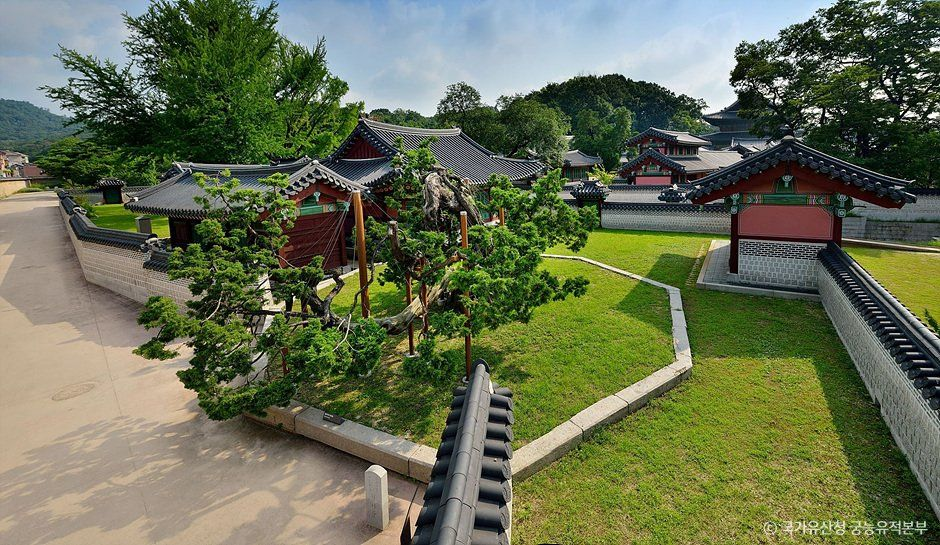

In [12]:
#추출된 url로 사진을 임베딩하기 위해 다운로드
import requests
from PIL import Image
from io import BytesIO

# 사진 주소로 요청 보내기
response = requests.get(image_url, timeout=30)

# 다운로드에 실패했다면 오류 표시
response.raise_for_status()

# 내려받은 데이터를 이미지로 열기
image = Image.open(BytesIO(response.content)).convert("RGB")

# 노트북 화면에 사진 표시
display(image)

In [13]:
#임시 모델 준비
from transformers import AutoModel, AutoImageProcessor

# 사용할 SigLIP 2 Base 모델
model_name = "google/siglip2-base-patch16-224"

# 학습된 모델 불러오기
# safetensors 형식의 모델 파일 사용
model = AutoModel.from_pretrained(
    model_name,
    use_safetensors=True
)

# 사진을 모델에 맞는 크기와 픽셀 값으로 변환하는 도구
processor = AutoImageProcessor.from_pretrained(model_name)

# 학습이 아닌 추론 모드로 설정
model.eval()

print("SigLIP 2 모델 준비 완료")

/Users/yuheelim/projects/self/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SigLIP 2 모델 준비 완료


In [14]:
#모델에 사진 넣어 임베딩 벡터 만들기
import torch

# 사진을 모델이 받을 수 있는 입력 형태로 변환
inputs = processor(images = image, return_tensors = "pt")

# 사진을 모델에 넣어 임베딩 벡터 생성
# no_grad(): 학습용 계산 없이 벡터만 추출
with torch.no_grad():
    image_vector = model.get_image_features(**inputs)

# 결과 확인
print("벡터 크기:", image_vector.shape)
print("벡터 앞부분:", image_vector[0, :10])

벡터 크기: torch.Size([1, 768])
벡터 앞부분: tensor([ 0.1987,  0.0904,  0.3686, -0.0197,  0.3707, -0.3886,  0.3735, -0.1463,
         0.2976, -0.3788])


NumPy 버전: 1.26.4
PyTorch 버전: 2.2.2
